# Лабораторная работа №2 - Виртуальный датчик для контроля процесса обжига в печи

### Выполнил: Жеребцов Сергей
### Группа: М8О-203СВ-25

Требуется оценить текущую концентрацию по телеметрии и её истории, используя лабораторные пробы как правильные ответы. Названия приборов и единицы не указаны, поэтому используются имена telemetry_0 ... telemetry_15 и исходный масштаб target.


In [1]:
# Импорт библиотек
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
import statsmodels.api as sm
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.graphics.tsaplots import plot_acf
from threadpoolctl import threadpool_limits
import shap

LAB = Path.cwd()
RANDOM_STATE = 42
plt.rcParams.update({'font.size': 9, 'axes.grid': True, 'grid.alpha': .2})


## 1. Разведочный анализ данных

### 1.1. Загрузка и проверка

В телеметрии находятся дата и 16 показателей, в лабораторных файлах - дата и target, концентрация продукта. При загрузке проверяются повторы, пропуски и границы времени. Единицы и названия приборов не указаны, поэтому сохранён исходный масштаб данных.


In [ ]:
# загружаем телеметрию и объединяем повторные записи
def load_telemetry(path):
    raw = pd.read_csv(path, parse_dates=['datetime']).sort_values('datetime', kind='stable')
    distinct = raw.drop_duplicates()
    repeated = distinct[distinct['datetime'].duplicated(keep=False)]
    conflicts = repeated.groupby('datetime').nunique().gt(1).any(axis=1)
    # разные записи за одну минуту объединяем по медиане
    data = distinct.groupby('datetime').median(numeric_only=True).asfreq('min')
    report = {'Исходных строк': len(raw), 'Точных копий': int(raw.duplicated().sum()),
              'Конфликтных минут': int(conflicts.sum()), 'Минут после очистки': len(data)}
    return raw, data, report


# загружаем лабораторные ответы с датой в индексе
def load_target(path):
    data = pd.read_csv(path)
    data = data.rename(columns={data.columns[0]: 'record_time'})
    data['record_time'] = pd.to_datetime(data['record_time'])
    data = data.sort_values('record_time').set_index('record_time')
    assert data.index.is_unique and data['target'].notna().all()
    return data['target'].astype(float)


raw_train, data_train, audit_train = load_telemetry(LAB / 'data_train.csv')
target_original = load_target(LAB / 'target_train.csv')
columns = data_train.columns.tolist()
for name, count in audit_train.items():
    print(name + ':', count)
print("Период телеметрии:", data_train.index.min(), '...', data_train.index.max())
print('Лабораторных проб:', len(target_original))

# показываем исходные строки с разными значениями за одно время
unique_rows = raw_train.drop_duplicates()
same_time = unique_rows[unique_rows['datetime'].duplicated(keep=False)]
for moment, rows in same_time.groupby('datetime'):
    changed = rows.nunique().gt(1)
    changed_columns = changed[changed].index.tolist()
    if changed_columns:
        print('Различающиеся записи:', moment.strftime('%d.%m.%Y %H:%M:%S'))
        for column in changed_columns:
            print(column + ':', rows[column].round(6).tolist())

inside = (target_original.index >= data_train.index.min()) & (target_original.index <= data_train.index.max())
target = target_original.loc[inside].copy()
print('Проб после ограничения по времени:', len(target))
for moment, value in target_original.loc[~inside].items():
    print('Проба вне телеметрии:', moment, '; target:', round(value, 6))
validation_start = target.index[int(len(target) * .8)]
eda = data_train.loc[data_train.index < validation_start]
eda_target = target.loc[target.index < validation_start]


Исходных строк: 319546
Точных копий: 1547
Конфликтных минут: 1
Минут после очистки: 317998
Период телеметрии: 2019-03-01 00:01:00 ... 2019-10-07 19:58:00
Лабораторных проб: 1773
Различающиеся записи: 27.08.2019 00:00:00
telemetry_12: [0.285714, 0.515528]
telemetry_13: [0.71, 0.47]
telemetry_14: [0.454545, 0.443182]
telemetry_15: [0.350299, 0.206587]
Проб после ограничения по времени: 1772
Проба вне телеметрии: 2019-10-07 21:00:00 ; target: 0.134021


Удалены 1547 точных копий. В двух строках за 27.08.2019, 00:00, различались четыре показателя; для них взята медиана. Это выбранный способ разрешить конфликт при отсутствии журнала исправлений.

После очистки получено 317998 минут. Из 1773 проб исключена последняя, за 7 октября в 21:00: телеметрия заканчивается в 19:58. Осталось 1772 пробы. Измеренные нули сохранены.

### 1.2. Пропуски и динамика телеметрии

Для EDA взята ранняя часть train до начала validation 24 августа. На минутной сетке сравнивается доля пропусков по дням. Отсутствующие записи при загрузке не заполнялись.


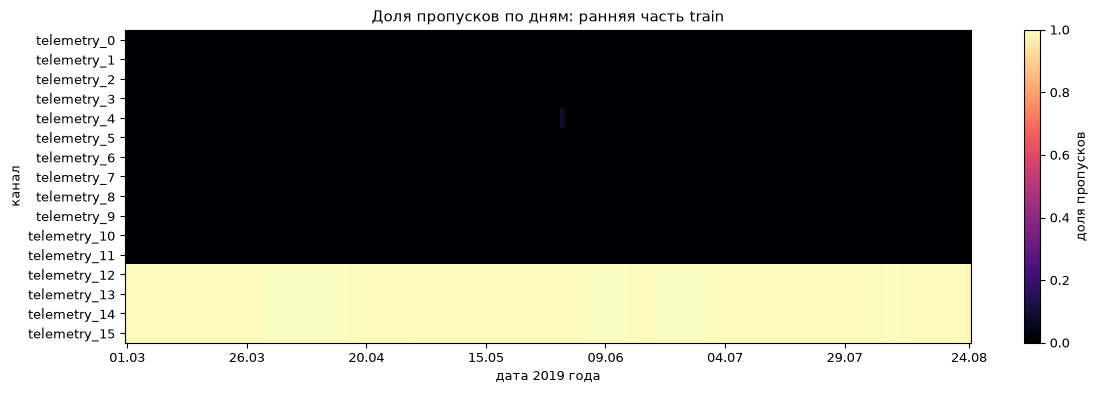

telemetry_0 ... telemetry_11: обычный шаг 1 мин, в среднем 0.01% пустых минут.
telemetry_12 ... telemetry_15: обычный шаг 120 мин, в среднем 99.37% пустых минут.


In [ ]:
daily_missing = eda.isna().resample('D').mean().T
fig, ax = plt.subplots(figsize=(12, 4))
img = ax.imshow(daily_missing, aspect='auto', vmin=0, vmax=1, cmap='magma')
positions = np.linspace(0, len(daily_missing.columns) - 1, 8, dtype=int)
ax.set_xticks(positions, [daily_missing.columns[i].strftime('%d.%m') for i in positions])
ax.set_yticks(range(len(columns)), columns)
ax.set(title='Доля пропусков по дням: ранняя часть train', xlabel='дата 2019 года', ylabel='канал')
ax.grid(False)
fig.colorbar(img, ax=ax, label='доля пропусков')
fig.tight_layout()
plt.show()

# частоту записи проверяем отдельно для двух групп каналов
for group in [columns[:12], columns[12:]]:
    steps, missing = [], []
    for column in group:
        gap = eda[column].dropna().index.to_series().diff().dt.total_seconds() / 60
        steps.append(gap.median())
        missing.append(100 * eda[column].isna().mean())
    print(f'{group[0]} ... {group[-1]}: обычный шаг {np.median(steps):g} мин, '
          f'в среднем {np.mean(missing):.2f}% пустых минут.')


Каналы 0-11 обычно записываются каждую минуту, каналы 12-15 - раз в два часа. Поэтому у последних около 99% пустых минут и светлые строки на карте. При заполнении пропусков дальше учитывается разная частота записи.

Для просмотра трендов сравниваются дневные средние и сглаживание за семь дней. Усреднение используется только на рисунках.


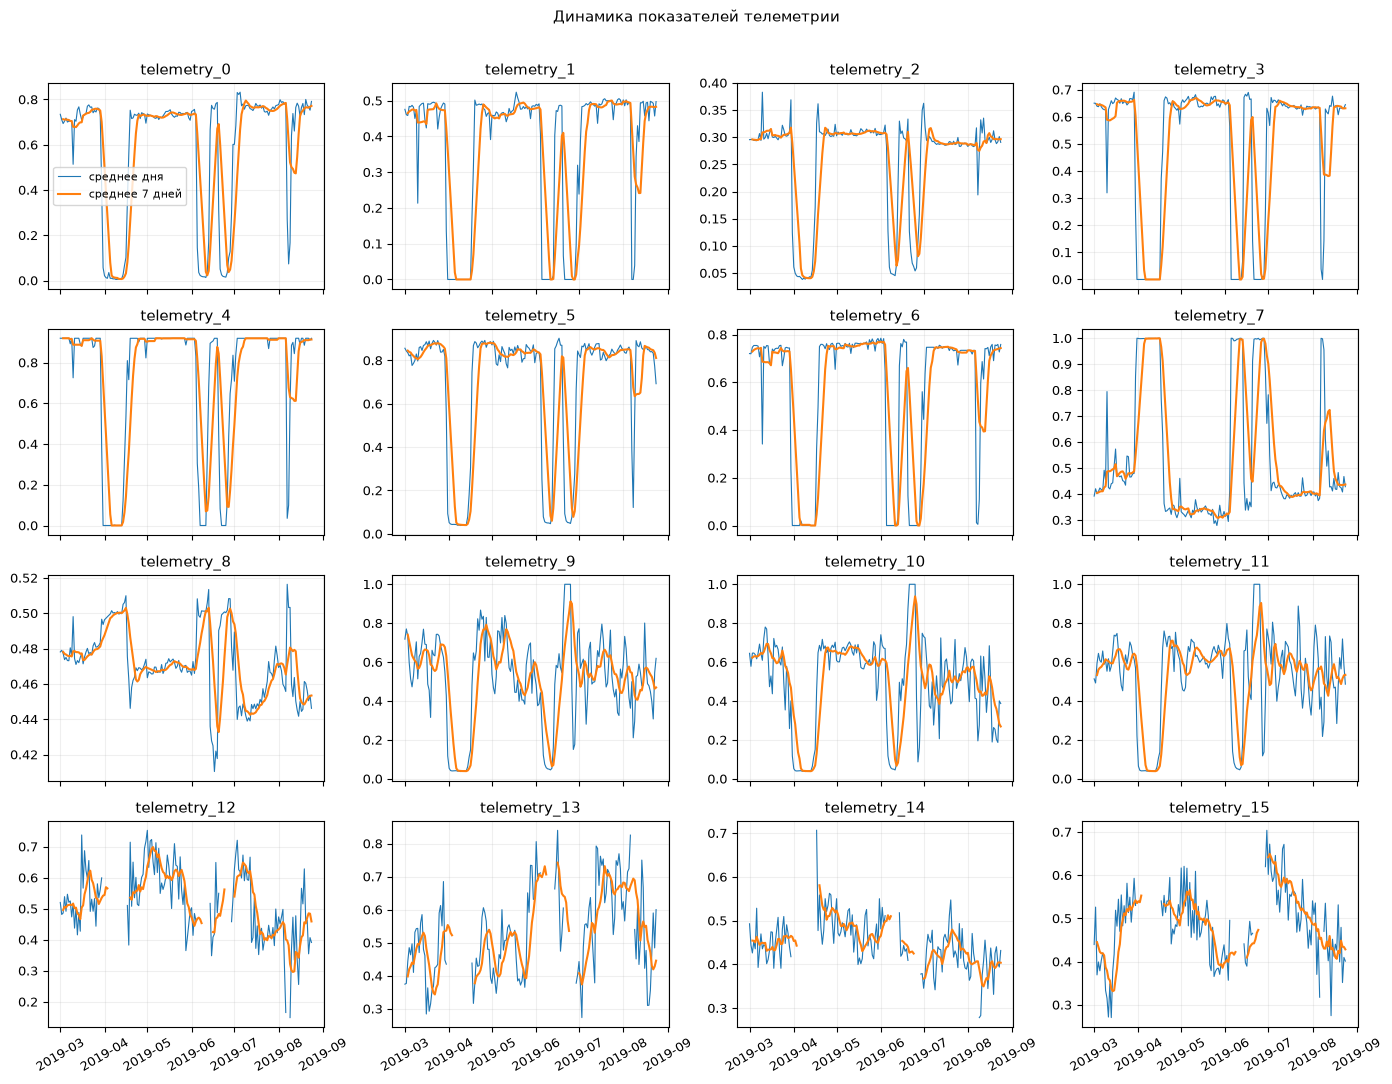

In [ ]:
fig, axes = plt.subplots(4, 4, figsize=(14, 11), sharex=True)
for column, ax in zip(columns, axes.ravel()):
    daily = eda[column].resample('D').mean()
    ax.plot(daily.index, daily, linewidth=.8, label='среднее дня')
    ax.plot(daily.index, daily.rolling(7, min_periods=3).mean(), label='среднее 7 дней')
    ax.set_title(column)
    ax.tick_params(axis='x', labelrotation=30)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Динамика показателей телеметрии")
fig.tight_layout(rect=(0, 0, 1, .97))
plt.show()


У ряда каналов видны совпадающие провалы и изменения уровня. По этим графикам явный устойчивый сезонный цикл не выделяется. Причина провалов без описания приборов неизвестна, поэтому нулевые значения не удалялись.

### 1.3. Лабораторные пробы и необычные значения

Ниже сравниваются концентрация во времени, её распределение и интервалы между пробами.


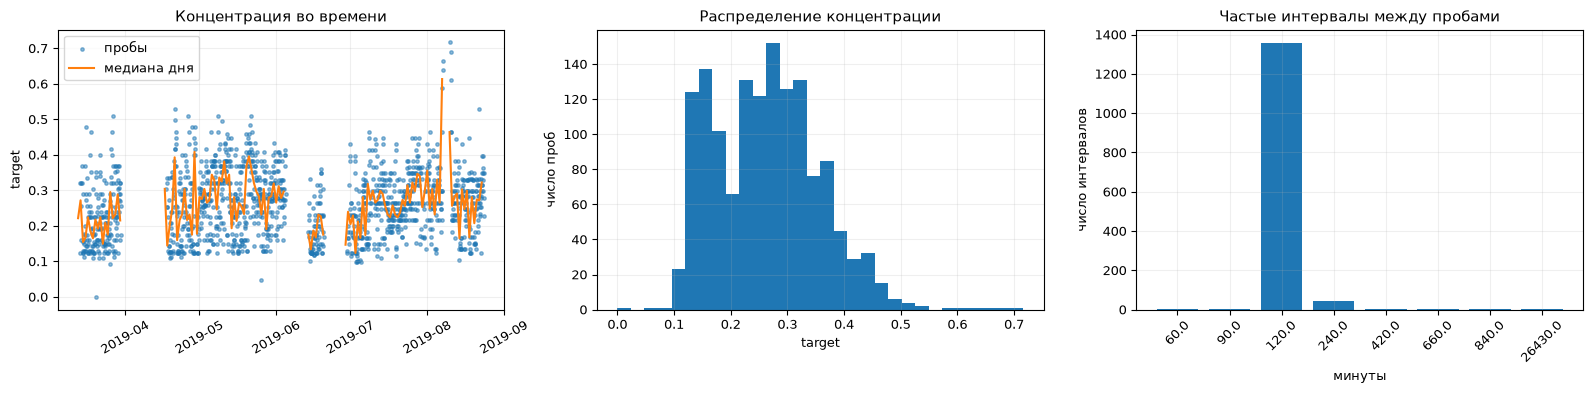

In [ ]:
gaps = eda_target.index.to_series().diff().dt.total_seconds() / 60
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(eda_target.index, eda_target, s=6, alpha=.5, label='пробы')
daily_target = eda_target.resample('D').median()
axes[0].plot(daily_target.index, daily_target, color='tab:orange', label='медиана дня')
axes[0].set(title='Концентрация во времени', ylabel='target')
axes[0].tick_params(axis='x', labelrotation=30)
axes[0].legend()
axes[1].hist(eda_target, bins=30)
axes[1].set(title='Распределение концентрации', xlabel='target', ylabel='число проб')
frequent_gaps = gaps.value_counts().head(8).sort_index()
axes[2].bar(frequent_gaps.index.astype(str), frequent_gaps.values)
axes[2].set(title='Частые интервалы между пробами', xlabel='минуты', ylabel='число интервалов')
axes[2].tick_params(axis='x', labelrotation=45)
fig.tight_layout()
plt.show()


Большинство проб взято с интервалом два часа, но есть более длинные перерывы. Концентрация заметно меняется, встречаются отдельные высокие значения. Неизвестные ответы между настоящими пробами не создавались.

Для поиска необычных показаний применяется правило 1.5 IQR. Оно отмечает значения ниже Q1 - 1.5 IQR или выше Q3 + 1.5 IQR, где IQR = Q3 - Q1.


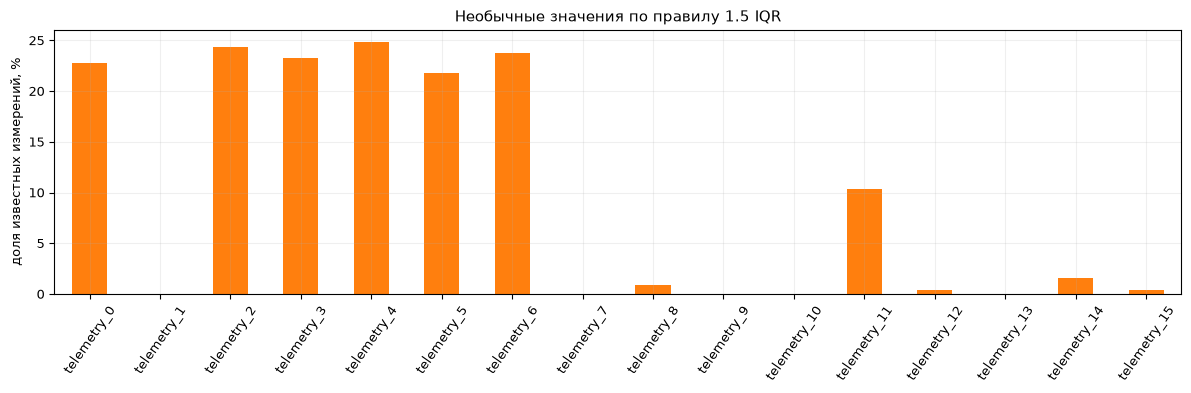

In [ ]:
q1, q3 = eda.quantile(.25), eda.quantile(.75)
iqr = q3 - q1
flags = eda.lt(q1 - 1.5 * iqr) | eda.gt(q3 + 1.5 * iqr)
outlier_share = 100 * flags.sum() / eda.notna().sum()
outlier_share[iqr.eq(0)] = np.nan
fig, ax = plt.subplots(figsize=(12, 4))
outlier_share.plot.bar(ax=ax, color='tab:orange')
ax.set(title='Необычные значения по правилу 1.5 IQR', ylabel='доля известных измерений, %')
ax.tick_params(axis='x', labelrotation=55)
fig.tight_layout()
plt.show()


У некоторых каналов правило отмечает заметную долю значений. Они могут относиться к другому режиму работы, поэтому автоматически не обрезались. Физические пределы показателей не заданы.

### 1.4. Синхронизация

Принято, что дата target означает время отбора пробы, а лабораторный ответ доступен через 15 минут. Телеметрия считается доступной в указанную минуту. Признаки строятся на время пробы по текущим и прошлым показаниям, без будущих данных. Смысл даты target отдельно в файлах не уточнён.

### Вывод по разделу 1

Подготовлена минутная сетка из 317998 минут и оставлены 1772 реальные пробы в границах train. Каналы имеют разную частоту записи, поэтому для них нужны разные пределы переноса прошлого значения. Совпадающие провалы и высокая доля отметок IQR не дают оснований удалять все нули и необычные значения без сведений о процессе. Для обучения используются только настоящие лабораторные ответы, а их доступность определяется принятым допущением о задержке 15 минут. Эти решения сохраняют наблюдаемые изменения данных и позволяют строить признаки без сведений из будущего.



## 2. Подготовка признаков

### 2.1. Признаки и разделение по времени

В признаки входят текущие значения, лаги, скользящие статистики и изменения показаний. Выборка делится по времени: ранние пробы идут в fit, более поздние - в validation.

Прошлое значение переносится не более чем на 30 минут для каналов 0-11 и на 240 минут для каналов 12-15. Перенос ограничен, чтобы старое показание не считалось актуальным во время длительного перерыва. Для скользящего окна нужна хотя бы половина значений. Остальные пропуски заполняются медианами обучающей части: медиана меньше зависит от крайних значений, чем среднее.


In [ ]:
# собираем признаки из текущей и прошлой телеметрии
def feature_matrix(telemetry, sample_times):
    sample_times = pd.DatetimeIndex(sample_times)
    assert telemetry.index.is_unique and telemetry.index.is_monotonic_increasing
    assert sample_times.isin(telemetry.index).all()
    result = {}
    clock = telemetry.index.to_series()
    for column in telemetry.columns:
        raw = telemetry[column]
        # старое показание переносится только до заданного срока
        last_seen = clock.where(raw.notna()).ffill()
        age = (clock - last_seen).dt.total_seconds() / 60
        limit = 240 if int(column.split('_')[-1]) >= 12 else 30
        values = raw.ffill().where(age.le(limit))
        prefix = column + '__'
        # признаки оставляем только на датах настоящих проб
        result[prefix + 'current'] = values.reindex(sample_times).to_numpy()
        for lag in [5, 60]:
            result[prefix + f'lag_{lag}'] = values.shift(lag).reindex(sample_times).to_numpy()
        # для расчёта окна нужна хотя бы половина значений
        for window in [60, 180]:
            rolling = values.rolling(window, min_periods=window // 2)
            result[prefix + f'mean_{window}'] = rolling.mean().reindex(sample_times).to_numpy()
            result[prefix + f'std_{window}'] = rolling.std().reindex(sample_times).to_numpy()
            result[prefix + f'min_{window}'] = rolling.min().reindex(sample_times).to_numpy()
            result[prefix + f'max_{window}'] = rolling.max().reindex(sample_times).to_numpy()
        previous = values.shift(15)
        result[prefix + 'change_15'] = (values - previous).reindex(sample_times).to_numpy()
        # возле нуля относительное изменение получается слишком большим
        growth = (values - previous) / previous.abs().where(previous.abs() > 1e-6)
        result[prefix + 'relative_change_15'] = growth.reindex(sample_times).to_numpy()
    return pd.DataFrame(result, index=sample_times).replace([np.inf, -np.inf], np.nan)

# признаки и ответы оставляем только на датах реальных проб
y = target.copy()
X = feature_matrix(data_train, y.index)
# в fit остаются ответы, уже доступные к началу проверки
fit_mask = (y.index < validation_start) & (y.index + pd.Timedelta(minutes=15) <= validation_start)
val_mask = y.index >= validation_start
X_fit, y_fit = X.loc[fit_mask], y.loc[fit_mask]
X_val, y_val = X.loc[val_mask], y.loc[val_mask]
assert X.shape == (1772, 208)
assert len(y_fit) == 1417 and len(y_val) == 355
assert X.index.equals(y.index) and X_fit.index.max() < X_val.index.min()
assert (y_fit.index + pd.Timedelta(minutes=15)).max() <= validation_start

print('Признаки:', X.shape)
print('Fit:', len(y_fit), 'проб;', y_fit.index.min(), '...', y_fit.index.max())
print('Validation:', len(y_val), 'проб;', y_val.index.min(), '...', y_val.index.max())


Признаки: (1772, 208)
Fit: 1417 проб; 2019-03-13 17:00:00 ... 2019-08-23 23:00:00
Validation: 355 проб; 2019-08-24 01:00:00 ... 2019-10-07 19:00:00


На каждый канал рассчитано 13 признаков: текущий уровень, лаги 5 и 60 минут, mean/std/min/max за 60 и 180 минут, разность и относительное изменение за 15 минут. Всего получено 208 столбцов. Так представлены недавний уровень, более длинная история и изменение показаний.

Первые 1417 проб выделены для fit, последние 355 - для validation. В fit оставлены только ответы, которые уже должны быть известны к началу проверки с учётом задержки 15 минут.

### 2.2. Связь признаков с концентрацией

Для текущих значений и выбранных лагов рассчитываются корреляции Спирмена с target только на fit.


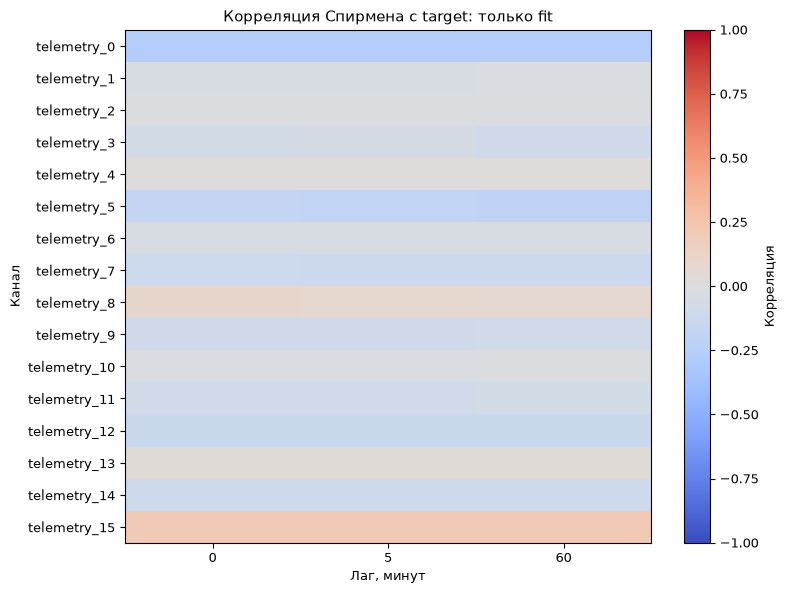

Самая заметная связь среди текущих показаний: telemetry_0, корреляция Спирмена -0.270.


In [ ]:
# сравниваем текущие значения и два лага только на fit
lag_grid = [0, 5, 60]
lag_correlations = pd.DataFrame(index=columns, columns=lag_grid, dtype=float)
for column in columns:
    for lag in lag_grid:
        name = column + '__' + ('current' if lag == 0 else f'lag_{lag}')
        lag_correlations.loc[column, lag] = X_fit[name].corr(y_fit, method='spearman')
fig, ax = plt.subplots(figsize=(8, 6))
img = ax.imshow(lag_correlations, vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
ax.set_xticks(range(len(lag_grid)), lag_grid)
ax.set_yticks(range(len(columns)), columns)
ax.set_xlabel('Лаг, минут')
ax.set_ylabel('Канал')
ax.set_title('Корреляция Спирмена с target: только fit')
ax.grid(False)
fig.colorbar(img, ax=ax, label='Корреляция')
plt.tight_layout()
plt.show()

current_corr = lag_correlations[0]
strongest = current_corr.abs().idxmax()
print(f'Самая заметная связь среди текущих показаний: {strongest}, '
      f'корреляция Спирмена {current_corr[strongest]:.3f}.')


Среди текущих значений самая заметная связь у telemetry_0: -0.270. По модулю она невелика. Карта также показывает, как связь меняется при сдвиге показаний в прошлое.

### Вывод по разделу 2

Из 16 каналов получено 208 признаков, которые описывают текущие уровни, прошлые значения, разброс и изменения показаний. Для обучения выделено 1417 ранних проб, для validation оставлено 355 более поздних проб. Такое разделение проверяет перенос модели на следующий период, а расчёт признаков только по доступному прошлому соответствует работе текущего датчика. Признаки сохраняют названия каналов и понятный смысл временных операций, что позволяет затем проверить, какие части истории использует модель. Отдельный отбор и PCA не применялись: в Pipeline удаляются константы, Ridge ограничивает коэффициенты, а деревья выбирают полезные разделения при обучении. Подготовленный набор даёт несколько способов описать один канал, однако польза всего набора оценивается по результатам проверки, а не по числу созданных столбцов.



## 3. Построение моделей

### 3.1. Три основных подхода

Ridge задаёт линейную связь с признаками. Штраф на коэффициенты помогает при похожих лагах, перед обучением применяется масштабирование.

RandomForest усредняет прогнозы деревьев и учитывает нелинейные сочетания показателей. Минимальный размер листа 8 ограничивает подстройку под отдельные пробы.

HistGradientBoosting последовательно добавляет деревья, уменьшая ошибку. Небольшой шаг обучения и L2-регуляризация ограничивают сложность.

Для сравнения зафиксированы настройки трёх моделей. Пропуски заполняются и константы удаляются внутри Pipeline, обученного только на fit.


In [ ]:
# объединяем обработку пропусков и обучение модели
def make_pipeline(model):
    return Pipeline([
        ('fill', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('constant', VarianceThreshold()),
        ('scale', StandardScaler() if isinstance(model, Ridge) else 'passthrough'),
        ('model', model)
    ])

# настройки фиксируем до проверки на validation
models_main = {
    'Ridge': make_pipeline(Ridge(alpha=100.)),
    'RandomForest': make_pipeline(RandomForestRegressor(
        n_estimators=180, min_samples_leaf=8, max_features=.7,
        n_jobs=2, random_state=RANDOM_STATE)),
    'HistGradientBoosting': make_pipeline(HistGradientBoostingRegressor(
        max_iter=250, learning_rate=.05, max_leaf_nodes=31,
        min_samples_leaf=20, l2_regularization=5.,
        early_stopping=False, random_state=RANDOM_STATE))
}


### 3.2. Выбор модели на validation

MAE показывает средний абсолютный промах, RMSE сильнее учитывает большие ошибки. MAPE и WAPE выражают относительные ошибки в процентах. WAPE делит сумму абсолютных ошибок на сумму абсолютных target. При нулевом факте обычная MAPE не определена, такие пробы остаются в остальных расчётах.

DA - доля совпадений направления соседних изменений факта и прогноза. Учитываются пары с промежутком не больше четырёх часов; отсутствие изменения считается отдельным направлением. Также подсчитывается число таких пар.

Для сравнения берутся два простых ориентира: среднее обучающих ответов и последняя доступная проба. Второй обновляется по мере поступления результатов с задержкой 15 минут. Основные модели используют только телеметрию.


In [ ]:
# считаем ошибки и совпадение направлений соседних изменений
def score_prediction(y, prediction):
    actual = y.to_numpy(dtype=float)
    prediction = np.asarray(prediction, dtype=float)
    assert prediction.ndim == 1 and len(actual) == len(prediction)
    assert np.isfinite(actual).all() and np.isfinite(prediction).all()
    error = actual - prediction
    zero = np.isclose(actual, 0.)
    mape = np.nan if zero.any() else 100 * np.mean(np.abs(error / actual))
    # направление сравниваем у проб с перерывом до четырёх часов
    gaps = y.index.to_series().diff().dt.total_seconds().to_numpy()[1:] / 60
    good_pair = (gaps > 0) & (gaps <= 240)
    direction_match = np.sign(np.diff(actual)) == np.sign(np.diff(prediction))
    da = 100 * direction_match[good_pair].mean() if good_pair.any() else np.nan
    total = np.abs(actual).sum()
    return {
        'MAE': np.abs(error).mean(),
        'RMSE': np.sqrt(np.mean(error ** 2)),
        'MAPE_%': mape,
        'WAPE_%': 100 * np.abs(error).sum() / total if total > 0 else np.nan,
        'DA_%': da,
        'DA_pairs': int(good_pair.sum())
    }

# берём последний ответ с учётом задержки лаборатории
def last_available_baseline(target_history, sample_times, delay_minutes=15):
    sample_times = pd.DatetimeIndex(sample_times)
    right = pd.DataFrame({
        'available_time': target_history.index + pd.Timedelta(minutes=delay_minutes),
        'previous_target': target_history.to_numpy()
    })
    left = pd.DataFrame({'sample_time': sample_times, 'position': np.arange(len(sample_times))})
    # к каждой пробе подбираем последний уже доступный ответ
    joined = pd.merge_asof(
        left.sort_values('sample_time'), right.sort_values('available_time'),
        left_on='sample_time', right_on='available_time', direction='backward')
    return joined.sort_values('position')['previous_target'].to_numpy()


In [ ]:
# обработку и модели обучаем только на fit
validation_predictions = pd.DataFrame(index=y_val.index)
for name, pipeline in models_main.items():
    model = clone(pipeline)
    with threadpool_limits(limits=2):
        model.fit(X_fit, y_fit)
        validation_predictions[name] = model.predict(X_val)

# сравниваем модели со средним и последней известной пробой
validation_predictions['Среднее_fit'] = y_fit.mean()
validation_predictions['Последняя_известная_проба'] = last_available_baseline(target_original, y_val.index)
validation_scores = {}
for name in validation_predictions:
    validation_scores[name] = score_prediction(y_val, validation_predictions[name])
preferred_name = min(models_main, key=lambda name: validation_scores[name]['RMSE'])
# показываем ошибки всех моделей и двух ориентиров
for name, result in validation_scores.items():
    print(f"{name}: RMSE {result['RMSE']:.4f}")

print('Предпочтительная модель по validation:', preferred_name,
      '; RMSE:', round(validation_scores[preferred_name]['RMSE'], 4))


Ridge: RMSE 0.0880
RandomForest: RMSE 0.0829
HistGradientBoosting: RMSE 0.0827
Среднее_fit: RMSE 0.0843
Последняя_известная_проба: RMSE 0.0823
Предпочтительная модель по validation: HistGradientBoosting ; RMSE: 0.0827


Среди трёх основных моделей на validation выбрана HistGradientBoosting: RMSE 0.0827. У среднего fit RMSE 0.0843, у последней доступной пробы 0.0823. Ошибка ниже, чем у среднего fit, но выше, чем у последней доступной пробы.

### 3.3. Информационные критерии

По AIC/BIC сравниваются две OLS-регрессии с 8 и 24 отобранными признаками на одних обучающих пробах. Меньшие AIC/BIC предпочтительнее. Это отдельное сравнение статистических моделей, без приписывания этих критериев лесу или бустингу. Предварительный отбор признаков в штрафе критериев не учитывается.


In [ ]:
# сравниваем информационные критерии двух линейных моделей
def fit_ols_candidates(X, y, sizes=(8, 24)):
    rows = {}
    for k in sizes:
        preprocessing = Pipeline([
            ('fill', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('constant', VarianceThreshold()),
            ('select', SelectKBest(f_regression, k=k)),
            ('scale', StandardScaler())
        ])
        with threadpool_limits(limits=2):
            values = preprocessing.fit_transform(X, y)
            model = sm.OLS(y.to_numpy(), sm.add_constant(values, has_constant='add')).fit()
        name = f'OLS_{k}'
        rows[name] = {'AIC': model.aic, 'BIC': model.bic,
                      'nobs': int(model.nobs), 'rank': int(model.df_model + 1)}
    return rows

# обе модели используют одни и те же обучающие пробы
ols_info = fit_ols_candidates(X, y)
for name, result in ols_info.items():
    assert result['nobs'] == len(y)
    print(f"{name}: AIC {result['AIC']:.2f}, BIC {result['BIC']:.2f}; ранг {result['rank']}.")


OLS_8: AIC -3541.12, BIC -3497.28; ранг 8.
OLS_24: AIC -3661.63, BIC -3530.11; ранг 24.


/tmp/ipykernel_11703/2710143648.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y.to_numpy(), sm.add_constant(values, has_constant='add')).fit()
/tmp/ipykernel_11703/2710143648.py:13: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(y.to_numpy(), sm.add_constant(values, has_constant='add')).fit()


По AIC предпочтительнее OLS_24, по BIC - OLS_24. У части признаков есть линейная зависимость: ранг меньше числа коэффициентов. Поэтому отдельные веса OLS могут определяться неоднозначно, что отражено в предупреждении библиотеки.

### 3.4. Неподходящие варианты

Обычный классификатор не подходит: требуется числовая концентрация. Признаки из будущего или ещё не полученный лабораторный ответ недоступны текущему датчику. Стандартную ARIMA по target нельзя напрямую применять как к регулярному ряду: пробы нерегулярны, а без внешних признаков телеметрия не используется. Нейросети возможны, но при небольшом числе меток в работе выбраны более простые табличные модели.

### Вывод по разделу 3

Для итоговой проверки выбрана HistGradientBoosting по минимальному RMSE на validation среди трёх основных моделей. Отрыв от RandomForest очень мал, а последняя доступная проба на этом периоде даёт меньшую ошибку. Поэтому выбор бустинга означает выбор кандидата для дальнейшей проверки, а не доказанное превосходство над всеми ориентирами. Отдельное сравнение OLS показало предпочтение варианта с 24 признаками по AIC и BIC, но не определяло выбор между Ridge, лесом и бустингом. Test при выборе не использовался, поэтому он позволяет проверить уже принятое решение на следующем периоде.

## 4. Оценка качества

### 4.1. Отдельный test

Для прошлых окон первых тестовых точек сохраняется история train. Ориентир последней пробы получает предыдущие тестовые ответы только после задержки 15 минут; основные модели на них не переобучаются.


In [ ]:
# для начала теста сохраняем прошлую телеметрию из train
raw_test, data_test, audit_test = load_telemetry(LAB / 'data_test_small.csv')
y_test_original = load_target(LAB / 'target_test_small.csv')
assert data_train.index.max() < data_test.index.min()
assert y.index.max() < y_test_original.index.min()
assert y_test_original.index.is_unique and y_test_original.index.is_monotonic_increasing
assert ((y_test_original.index >= data_test.index.min()) &
        (y_test_original.index <= data_test.index.max())).all()
all_telemetry = pd.concat([data_train, data_test]).asfreq('min')
y_test = y_test_original.copy()
X_test = feature_matrix(all_telemetry, y_test.index)
assert X_test.shape == (318, 208) and X_test.index.equals(y_test.index)

# заново обучаем три модели на всём train
final_models, fit_times = {}, {}
test_predictions = pd.DataFrame(index=y_test.index)
for name, pipeline in models_main.items():
    model = clone(pipeline)
    with threadpool_limits(limits=2):
        started = perf_counter()
        model.fit(X, y)
        fit_times[name] = perf_counter() - started
        test_predictions[name] = model.predict(X_test)
    final_models[name] = model

# предыдущие тестовые ответы доступны только через 15 минут
test_predictions['Среднее_train'] = y.mean()
target_history = pd.concat([target_original, y_test_original]).sort_index()
test_predictions['Последняя_известная_проба'] = last_available_baseline(target_history, y_test.index)
test_scores = {}
for name in test_predictions:
    test_scores[name] = score_prediction(y_test, test_predictions[name])
print('Тест:', len(y_test), 'проб;', y_test.index.min(), '...', y_test.index.max())

# сравниваем ошибки моделей и двух простых ориентиров
for name, result in test_scores.items():
    print(f"{name}: RMSE {result['RMSE']:.4f}, MAE {result['MAE']:.4f}, "
          f"MAPE {result['MAPE_%']:.2f}%, WAPE {result['WAPE_%']:.2f}%, "
          f"DA {result['DA_%']:.2f}%.")


Тест: 318 проб; 2019-10-07 23:00:00 ... 2019-11-04 09:00:00
Ridge: RMSE 0.0765, MAE 0.0614, MAPE 34.51%, WAPE 29.29%, DA 53.65%.
RandomForest: RMSE 0.0745, MAE 0.0607, MAPE 34.16%, WAPE 28.95%, DA 56.19%.
HistGradientBoosting: RMSE 0.0774, MAE 0.0626, MAPE 34.51%, WAPE 29.86%, DA 51.43%.
Среднее_train: RMSE 0.0919, MAE 0.0804, MAPE 48.47%, WAPE 38.33%, DA 5.08%.
Последняя_известная_проба: RMSE 0.0801, MAE 0.0595, MAPE 29.72%, WAPE 28.37%, DA 33.97%.


После выбора модели все три подхода переобучены на 1772 обучающих пробах. Качество рассчитано на 318 настоящих тестовых пробах.

На test у выбранной HistGradientBoosting RMSE 0.0774, MAE 0.0626, MAPE 34.51%, WAPE 29.86% и DA 51.43%. У последней доступной пробы RMSE 0.0801, у среднего train 0.0919. MAE выбранной модели больше, чем у последней доступной пробы; WAPE даёт тот же порядок, поскольку рассчитана на тех же ответах.


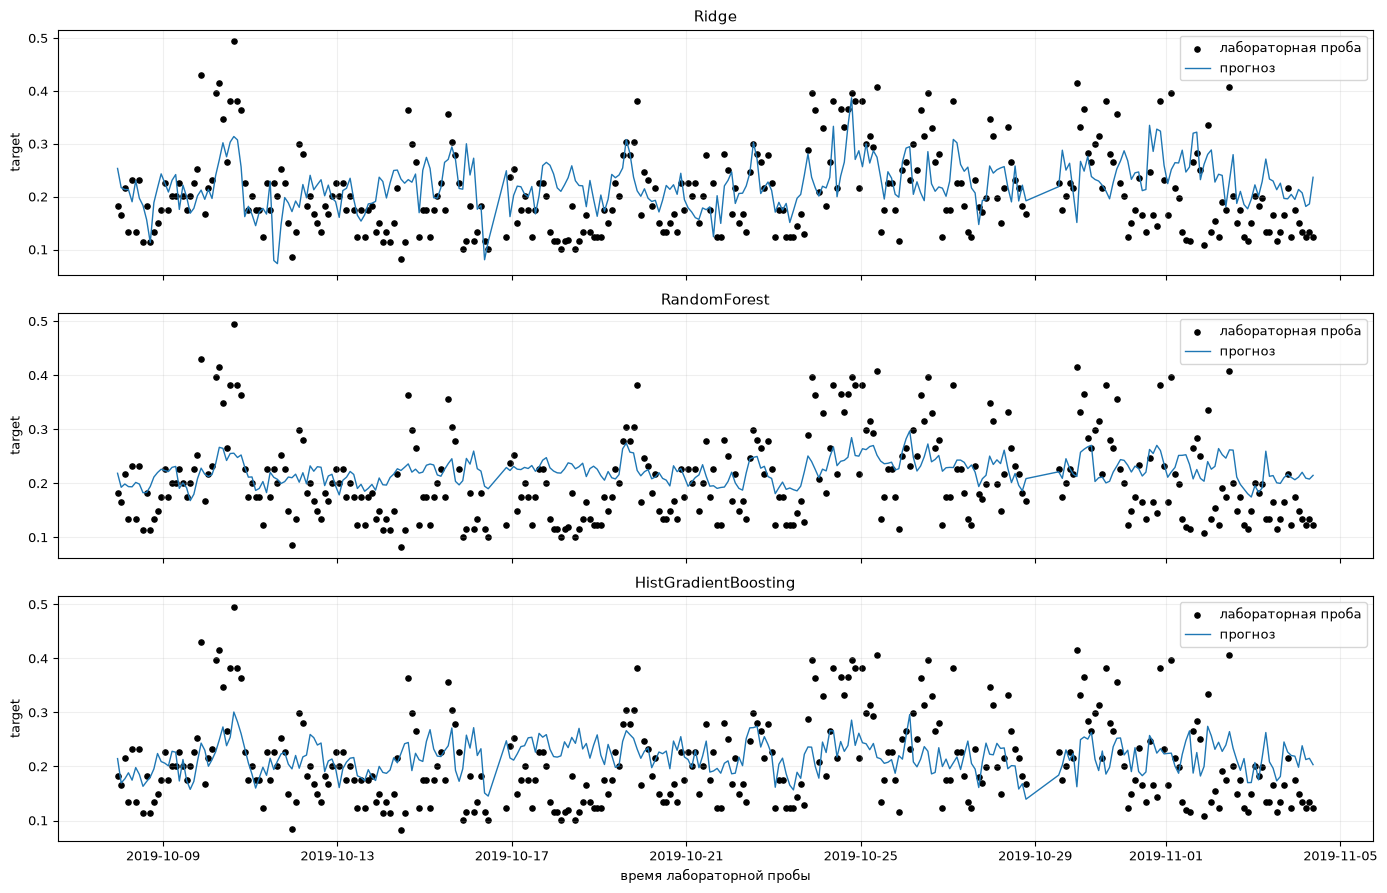

In [ ]:
# сравниваем прогноз с пробами в их исходные моменты времени
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for name, ax in zip(models_main, axes):
    ax.scatter(y_test.index, y_test, color='black', s=14, label='лабораторная проба')
    ax.plot(y_test.index, test_predictions[name], linewidth=1, label='прогноз')
    ax.set_title(name)
    ax.set_ylabel('target')
    ax.legend()
axes[-1].set_xlabel('время лабораторной пробы')
fig.tight_layout()
plt.show()


Линии соединяют оценки в моменты настоящих проб. Самые высокие значения target в среднем недооценены. Промежутки между точками не являются измеренной концентрацией.

### 4.2. Остатки

Ошибка определяется как факт минус прогноз. Проверяются нормальность тестом Ярке-Бера, автокорреляция тестом Льюнга-Бокса и постоянство разброса тестом Кёнкера-Бройша-Пагана относительно прогноза и времени. Для автокорреляции берётся самый длинный непрерывный участок с шагом 120 минут. При зависимых ошибках p-value рассматриваются вместе с графиками как приближённая диагностика.


In [ ]:
# проверяем свойства ошибок на тестовых лабораторных пробах
def residual_report(y, predictions):
    assert predictions.index.equals(y.index)
    assert y.index.is_unique and y.index.is_monotonic_increasing
    assert np.isfinite(y.to_numpy()).all() and np.isfinite(predictions.to_numpy()).all()
    errors = predictions.rsub(y, axis=0)

    # разрывы делят ряд на части, для проверки берётся самая длинная
    groups = y.index.to_series().diff().ne(pd.Timedelta(minutes=120)).cumsum()
    regular = errors.loc[groups.eq(groups.value_counts().idxmax())].copy()
    lag = min(12, len(regular) // 5)
    elapsed = (y.index - y.index[0]).total_seconds().to_numpy(dtype=float)
    elapsed = (elapsed - elapsed.mean()) / elapsed.std()

    rows = {}
    for name in predictions:
        error = errors[name].to_numpy()
        prediction = predictions[name].to_numpy()
        standardized_prediction = (prediction - prediction.mean()) / prediction.std()
        exog = sm.add_constant(np.column_stack([standardized_prediction, elapsed]),
                               has_constant='add')
        rows[name] = {
            'JB_p': jarque_bera(error)[1],
            'LjungBox_p': acorr_ljungbox(regular[name], lags=[lag], model_df=0,
                                       return_df=True)['lb_pvalue'].iloc[0],
            'BP_F_p': het_breuschpagan(error, exog, robust=True)[3],
        }
    return rows, regular


diagnostic_names = list(models_main)
diagnostics, regular_errors = residual_report(y_test, test_predictions[diagnostic_names])
print('Непрерывный участок для проверки автокорреляции:', len(regular_errors),
      'проб с шагом 120 минут.')
for name, result in diagnostics.items():
    print(f"{name}: p нормальности {result['JB_p']:.2e}, "
          f"автокорреляции {result['LjungBox_p']:.2e}, постоянства разброса {result['BP_F_p']:.2e}.")


Непрерывный участок для проверки автокорреляции: 144 проб с шагом 120 минут.
Ridge: p нормальности 1.51e-04, автокорреляции 2.47e-08, постоянства разброса 1.65e-02.
RandomForest: p нормальности 2.71e-07, автокорреляции 9.75e-14, постоянства разброса 3.35e-06.
HistGradientBoosting: p нормальности 3.65e-05, автокорреляции 1.12e-25, постоянства разброса 1.60e-05.


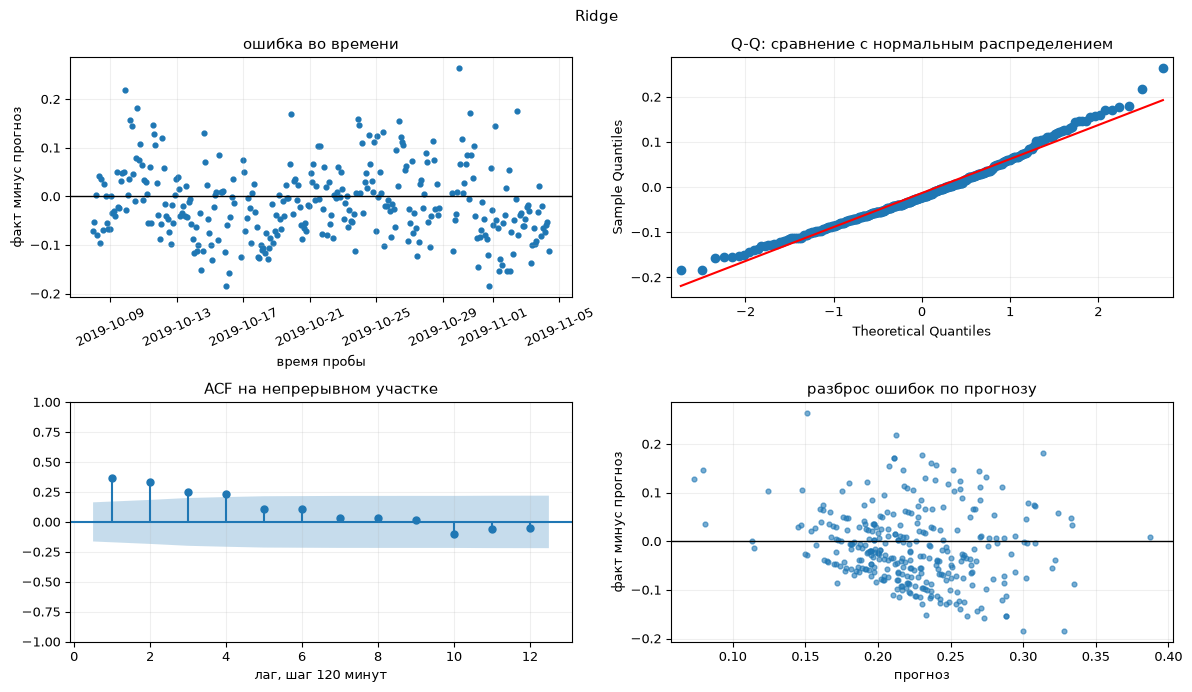

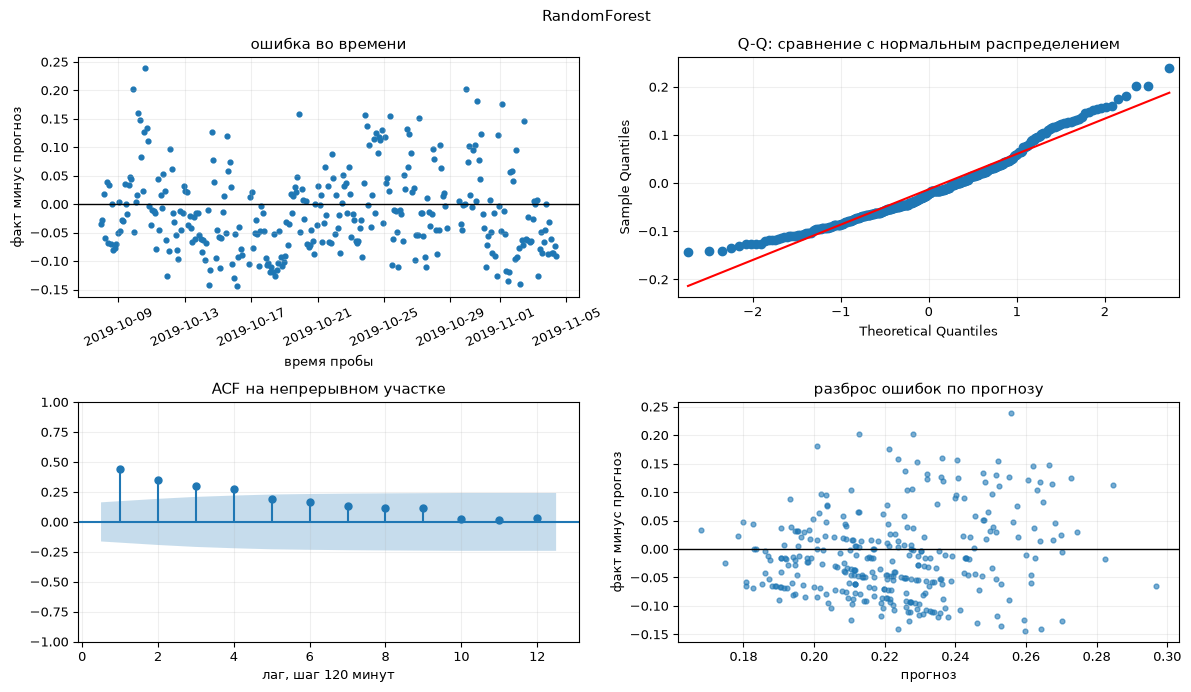

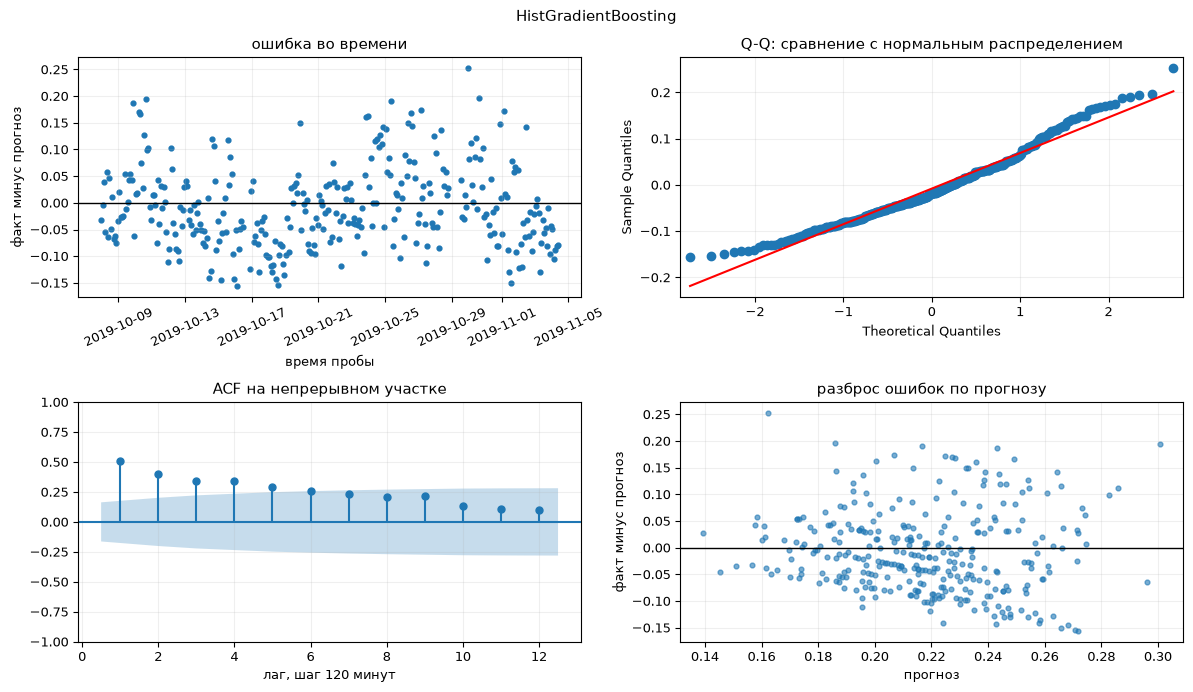

In [ ]:
# смотрим распределение, связь по времени и разброс ошибок
for name in diagnostic_names:
    errors = y_test - test_predictions[name]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    axes[0, 0].scatter(errors.index, errors, s=12)
    axes[0, 0].axhline(0, color='black', linewidth=1)
    axes[0, 0].set(title='ошибка во времени', xlabel='время пробы', ylabel='факт минус прогноз')
    axes[0, 0].tick_params(axis='x', labelrotation=25)
    sm.qqplot(errors, line='s', ax=axes[0, 1])
    axes[0, 1].set_title('Q-Q: сравнение с нормальным распределением')
    plot_acf(regular_errors[name], lags=min(12, len(regular_errors) // 5),
             zero=False, ax=axes[1, 0], title='ACF на непрерывном участке')
    axes[1, 0].set_xlabel('лаг, шаг 120 минут')
    axes[1, 1].scatter(test_predictions[name], errors, s=12, alpha=0.6)
    axes[1, 1].axhline(0, color='black', linewidth=1)
    axes[1, 1].set(title='разброс ошибок по прогнозу', xlabel='прогноз', ylabel='факт минус прогноз')
    fig.suptitle(name)
    fig.tight_layout()
    plt.show()


Для HistGradientBoosting проверка автокорреляции выполнена на 144 последовательных двухчасовых пробах. При уровне 0.05 отвергаются гипотезы нормальности, отсутствия автокорреляции, постоянного разброса относительно прогноза и времени. Проверки и графики показывают, какие свойства ошибок ещё не учтены моделью.

### 4.3. Важность признаков

Обычная перестановочная важность показывает рост RMSE после перемешивания отдельного признака у уже обученной модели. Похожие лаги могут частично заменять друг друга.


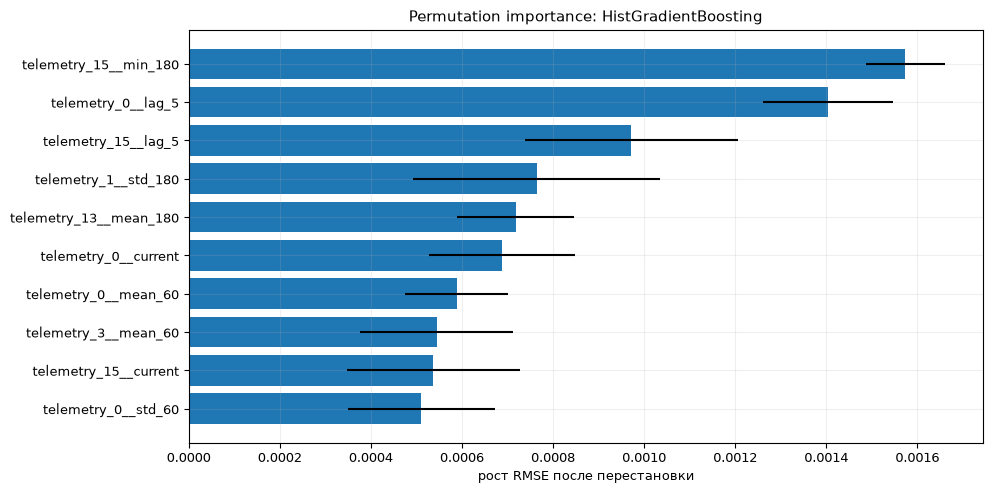

In [ ]:
# оцениваем важность признаков у модели, выбранной на валидации
best_pipeline = final_models[preferred_name]
# обработку берём из обучения, на test заново её не подгоняем
preprocessor = best_pipeline[:-1]
estimator = best_pipeline[-1]
feature_names = preprocessor.get_feature_names_out()
processed_test = pd.DataFrame(preprocessor.transform(X_test),
                              index=X_test.index, columns=feature_names)
processed_train = pd.DataFrame(preprocessor.transform(X), index=X.index, columns=feature_names)
with threadpool_limits(limits=2):
    # смотрим, насколько вырастет RMSE после перемешивания признака
    permutation = permutation_importance(
        estimator, processed_test.to_numpy(), y_test,
        scoring='neg_root_mean_squared_error', n_repeats=3,
        random_state=RANDOM_STATE, n_jobs=2,
    )
permutation_table = pd.DataFrame({
    'feature': feature_names,
    'mean': permutation.importances_mean,
    'std': permutation.importances_std,
}).sort_values('mean', ascending=False)
top = permutation_table.head(10).sort_values('mean')
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top['feature'], top['mean'], xerr=top['std'])
ax.set(xlabel='рост RMSE после перестановки', title='Permutation importance: ' + preferred_name)
fig.tight_layout()
plt.show()


В перестановочной важности первым оказался telemetry_15__min_180.

SHAP показывает вклад отдельных признаков в прогноз. Ниже объясняются оценки на части тестовых проб.


Число проб для SHAP: 100


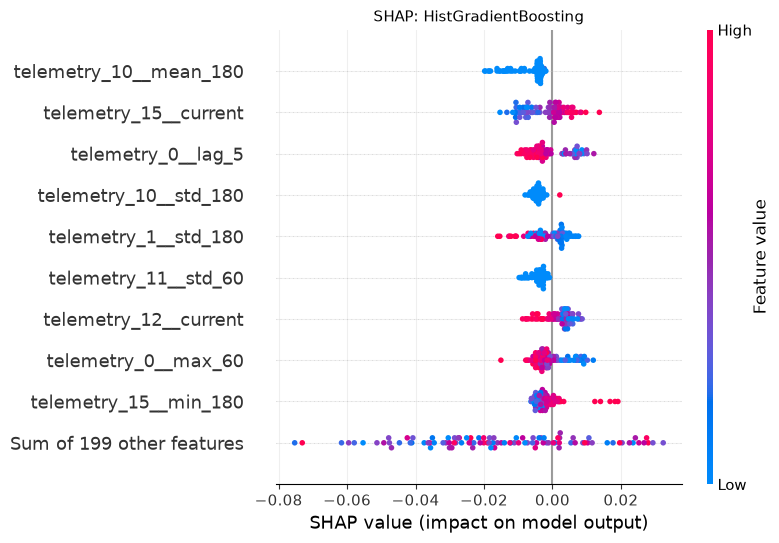

In [ ]:
# объясняем прогнозы в разных частях тестового периода
explain_positions = np.linspace(0, len(processed_test) - 1,
                                min(100, len(processed_test)), dtype=int)
explain_X = processed_test.iloc[explain_positions]
print('Число проб для SHAP:', len(explain_X))
if isinstance(estimator, Ridge):
    background = processed_train.sample(n=min(50, len(processed_train)), random_state=RANDOM_STATE)
    explainer = shap.LinearExplainer(estimator, background)
else:
    explainer = shap.TreeExplainer(estimator, feature_perturbation='tree_path_dependent')
# положительный вклад повышает прогноз, отрицательный снижает
shap_values = explainer(explain_X)
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.title('SHAP: ' + preferred_name)
plt.tight_layout()
plt.show()


Для SHAP равномерно выбраны 100 тестовых проб. В отдельных строках красные точки означают большие значения признака, синие - меньшие. Положительный вклад повышает прогноз относительно базового уровня модели, отрицательный понижает. Последняя строка объединяет остальные признаки.

По среднему модулю SHAP первым оказался telemetry_10__mean_180. На выбранных пробах вклады telemetry_15__current в прогноз в основном увеличиваются с ростом значения признака. Модель использует предыдущее состояние каналов, что согласуется с учётом динамики процесса. Каналы обезличены: связать результат с конкретной температурой или расходом без описания приборов нельзя. SHAP описывает прогноз модели, а не доказывает физическую причинность.

### 4.4. Время работы

Время обучения и прогноза измеряется при ограничении вычислений двумя потоками. Для predict после прогрева берётся среднее пяти запусков. Расчёт временных признаков в это время не входит.


In [ ]:
# измеряем прогноз на готовой матрице признаков вместе с обработкой в pipeline
speed = {}
for name in models_main:
    model = final_models[name]
    with threadpool_limits(limits=2):
        model.predict(X_test)
        start = perf_counter()
        for repeat in range(5):
            model.predict(X_test)
        seconds = (perf_counter() - start) / 5
    speed[name] = {
        'fit_seconds': fit_times[name],
        'predict_ms_for_test': seconds * 1000,
        'ms_per1000': seconds * 1000 / len(X_test) * 1000,
    }
    print(f'{name}: обучение {fit_times[name]:.2f} с, '
          f'прогноз {len(X_test)} проб за {seconds * 1000:.1f} мс.')


Ridge: обучение 0.02 с, прогноз 318 проб за 1.7 мс.


RandomForest: обучение 3.83 с, прогноз 318 проб за 48.0 мс.
HistGradientBoosting: обучение 1.89 с, прогноз 318 проб за 5.2 мс.


### Вывод по разделу 4

На test случайный лес дал наименьшую RMSE среди основных моделей: 0.0745. Выбранный по validation бустинг получил RMSE 0.0774 и превзошёл оба простых ориентира по этой метрике, однако последняя доступная проба оказалась лучше по MAE и WAPE. Поэтому итог зависит от того, что важнее: средний абсолютный промах или более сильный штраф за крупные ошибки.

По DA основные модели чаще совпадают с направлением изменений, чем ориентир последней пробы, но совпадение направления не гарантирует близкое значение концентрации. На графиках остаётся недооценка высоких пиков. Проверки остатков у всех трёх моделей выявили зависимость ошибок во времени и изменение их разброса, поэтому полученный прогноз ещё не описывает все изменения процесса.

## 5. Вывод

После очистки использованы 1772 обучающие и 318 тестовых лабораторных проб. Из минутной телеметрии создано 208 признаков, описывающих уровни показателей и их недавнюю историю.

| Модель или ориентир | RMSE validation | RMSE test | MAE test | WAPE test, % | DA test, % |
|---|---:|---:|---:|---:|---:|
| Ridge | 0.0880 | 0.0765 | 0.0614 | 29.29 | 53.65 |
| Случайный лес | 0.0829 | 0.0745 | 0.0607 | 28.95 | 56.19 |
| Бустинг (выбран) | 0.0827 | 0.0774 | 0.0626 | 29.86 | 51.43 |
| Среднее обучающей части | 0.0843 | 0.0919 | 0.0804 | 38.33 | 5.08 |
| Последняя доступная проба | 0.0823 | 0.0801 | 0.0595 | 28.37 | 33.97 |

Для validation среднее рассчитано по fit, для test - по полному train. RMSE и MAE приведены в исходных единицах target; WAPE показывает относительную ошибку, DA - долю совпавших направлений изменений.

По validation выбран бустинг, но его отрыв от леса составил всего около 0.0002 RMSE. На test порядок поменялся: лес оказался лучше и бустинга, и Ridge. Выбор модели после просмотра test не менялся. Разница результатов двух периодов показывает, что по одной проверке нельзя уверенно назвать один подход лучшим для всех следующих данных.

Последняя лабораторная проба остаётся сильным ориентиром: у неё наименьшие MAE и WAPE на test, хотя RMSE больше, чем у основных моделей. Все три модели чаще совпадают с направлением изменений, чем последняя доступная проба, но заметно сглаживают отдельные пики. Перед применением важно проверить, насколько допустимы такие промахи и сохраняется ли качество на следующем периоде.

Работа показывает возможность оценивать концентрацию по телеметрии. Качество проверено только в моменты настоящих лабораторных проб, поэтому результат не описывает точность между ними. Для применения в процессе нужно знать допустимую ошибку, назначение каналов и точный смысл времени target.
